# 01 · IR: A minimal first-pass baseline

Start with a deliberately simple baseline before trying more thoughtful data carpentry. We use recorded arrays as-is, sort coordinates, retain finite records covering the fixed bounds, interpolate every spectrum to 500 points and independently normalize it to 0–1. No advanced cleansing, category repair, duplicate-molecule removal within training, anomaly filtering or balancing is performed.

This is a **naïve starting point, not recommended production preprocessing**. No observations are fabricated or intentionally corrupted, and a worse score is not guaranteed. The worked examples investigate what a more careful approach changes. Validation and test remain the same frozen reference; training copies of held-out molecules are excluded for every method.

### Reading and presenting this notebook

Each code block has a descriptive heading followed by a short explanation labeled **Code Summary:**; saved outputs remain visible. In **VS Code**, open the Command Palette (`Ctrl+Shift+P` on Windows/Linux, `Cmd+Shift+P` on macOS) and choose **Notebook: Collapse All Cell Inputs** (search for `Collapse All Cell Inputs`). Use **Expand All Cell Inputs** to edit, or expand an individual cell using its input control. Do not collapse outputs. VS Code can remember your previous view, so use the command if code is still shown. In **JupyterLab**, code inputs are initially hidden via notebook metadata; expand them with the left-hand cell collapser or the View menu. Hiding code does not disable execution or remove it from the file.


### Load native spectra and reserve evaluation molecules

Code Summary: Loads native spectra, separates the frozen validation/test molecules from the training pool, and previews the fixed 500-point reference grid for a minimal preparation baseline.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from ir_carpentry import (load_native, ensure_frozen_evaluation, training_pool,
                         prepare_training, save_carpentry, validate_frozen_evaluation)
from examples.ir_example_support import validate_tables

MODULE = Path.cwd()
OUTPUT_DIR = MODULE / 'outputs/carpentry'
source, source_file = load_native(MODULE)
holdouts, grid, contract = ensure_frozen_evaluation(MODULE, source)
pool, excluded = training_pool(source, holdouts)
print(f'Native rows: {len(source):,}; training candidates: {len(pool):,}; held-out observations excluded: {excluded:,}')
print(f'Fixed bounds: {grid[0]:.2f}–{grid[-1]:.2f}; {len(grid)} points per spectrum.')
display(pool[['NIST_molecule', 'SMILES', 'x_raw', 'y_raw']].head(3))

[18:11:25] WARNING: not removing hydrogen atom without neighbors
[18:11:25] WARNING: not removing hydrogen atom without neighbors
[18:11:25] WARNING: not removing hydrogen atom without neighbors
[18:11:25] WARNING: not removing hydrogen atom without neighbors


Native rows: 11,001; training candidates: 9,027; held-out observations excluded: 1,974
Fixed bounds: 600.88–3846.00; 500 points per spectrum.


,NIST_molecule,SMILES,x_raw,y_raw
1,C91342335,CCC(C)NC1CCCCC1.Cl,"[2.013, 2.0178898, 2.0227796, 2.0276694, 2.032...","[0.932, 0.932, 0.932, 0.932, 0.932, 0.932, 0.9..."
9,C2510363,Cc1noc(C)c1C(=O)O,"[549.759, 551.688, 553.617, 555.546, 557.475, ...","[0.039951, 0.038491, 0.037741000000000004, 0.0..."
11,C66553320,CCC(CCl)CCCCCCCCCl,"[2.048, 2.0548192, 2.0616384, 2.0684576, 2.075...","[0.964, 0.964, 0.964, 0.96, 0.957, 0.955, 0.95..."


## A simple prompt

> Make a first-pass numeric training table from the recorded arrays. Sort coordinates and average repeats, reject malformed/nonfinite/flat records, keep complete coverage of the fixed reference bounds, interpolate to its 500 coordinates and min-max normalize each signal. Keep existing labels and repeated training molecules. Do not add advanced quality rules or rebalance. Preserve the fixed validation/test files, with no held-out identity in training.

### Create the minimal uniform-spectrum baseline

Code Summary: Uses the recorded numeric signals directly, retains spectra covering the full reference range, and linearly resamples them to a common grid. Each spectrum is min–max normalized, then plotted alongside preparation counts.


spectra
action   reason                                                     
kept     as_recorded_no_unit_handling;cropped_and_interp...     4848
rejected incomplete_measured_coverage                           3615
         invalid_identity                                        564

Resampling: {'downsampled_linear': 4848}
Uniform model matrix: (4848, 500)


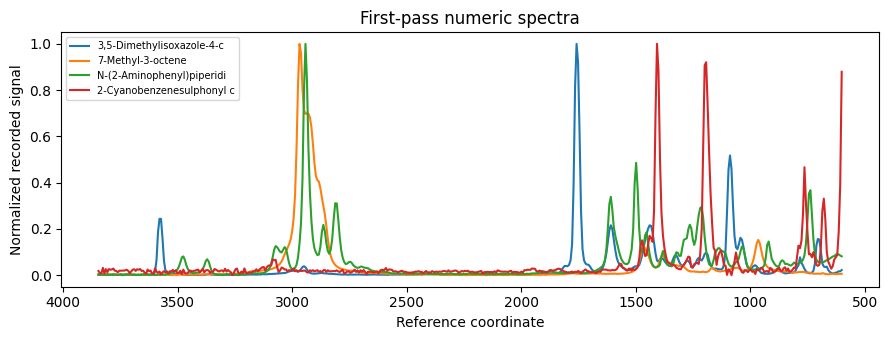

In [2]:
train, audit = prepare_training(pool, grid, signal_policy='as_recorded',
    bounds_policy='require_full_coverage', resampling='linear')
display(audit.groupby(['action', 'reason']).size().rename('spectra').to_frame())
print('Resampling:', train.resampling_action.value_counts().to_dict())
print('Uniform model matrix:', np.vstack(train.IR).shape)
fig, ax = plt.subplots(figsize=(9, 3.5))
for _, row in train.head(4).iterrows():
    ax.plot(grid, row.IR, label=str(row.Name)[:25])
ax.invert_xaxis(); ax.set(xlabel='Reference coordinate', ylabel='Normalized recorded signal', title='First-pass numeric spectra')
ax.legend(fontsize=7); fig.tight_layout(); plt.show()

### Save and validate the baseline training dataset

Code Summary: Saves the baseline training data, unchanged evaluation tables, and a manifest. Reloading checks uniform finite inputs, binary labels, and separated molecular identities before training in notebook 02.


In [3]:
choices = dict(signal_policy='as_recorded', bounds_policy='require_full_coverage',
    resampling='linear', normalization='per_spectrum_minmax', cleansing='none',
    training_identity_guard=True, description='naive numeric baseline; no advanced carpentry')
manifest = save_carpentry(MODULE, OUTPUT_DIR, train, source_file, choices, audit, len(source))
tables = {name: pd.read_parquet(OUTPUT_DIR / f'IR_{name}.parquet') for name in ('train', 'validation', 'test')}
validate_tables(tables, grid)
validate_frozen_evaluation(MODULE, OUTPUT_DIR, grid)
print('PASS: uniform finite features, binary labels, no training/held-out identity overlap and unchanged evaluation hashes.')
print('Rows:', manifest['rows'])
print("Next: run the four worked examples, then IR 02 with CARPENTRY_DIR = Path('outputs/carpentry') for this baseline.")

PASS: uniform finite features, binary labels, no training/held-out identity overlap and unchanged evaluation hashes.
Rows: {'input': 11001, 'train': 4848, 'validation': 975, 'test': 975}
Next: run the four worked examples, then IR 02 with CARPENTRY_DIR = Path('outputs/carpentry') for this baseline.


## Compare, do not assume

Examples **01a–01d** investigate different hypotheses and finish with the same model interface. Train all options with IR 02 and read the real results in IR 03. These are bundled strategies, not a controlled estimate of each individual step; different stopping times and a single random seed also limit conclusions. Do not select a policy by repeatedly consulting the test scores.